# Step 4: Feature Engineering and Baseline Model

## Objectives
- Load and prepare the dataset.
- Examine feature importance and redundancy.
- Establish a baseline classification model.
- Record initial evaluation metrics.

In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/phishing_dataset.csv")

X = df.drop(columns=["url", "label", "has_ip"])
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (31740, 14)
Testing set: (7936, 14)


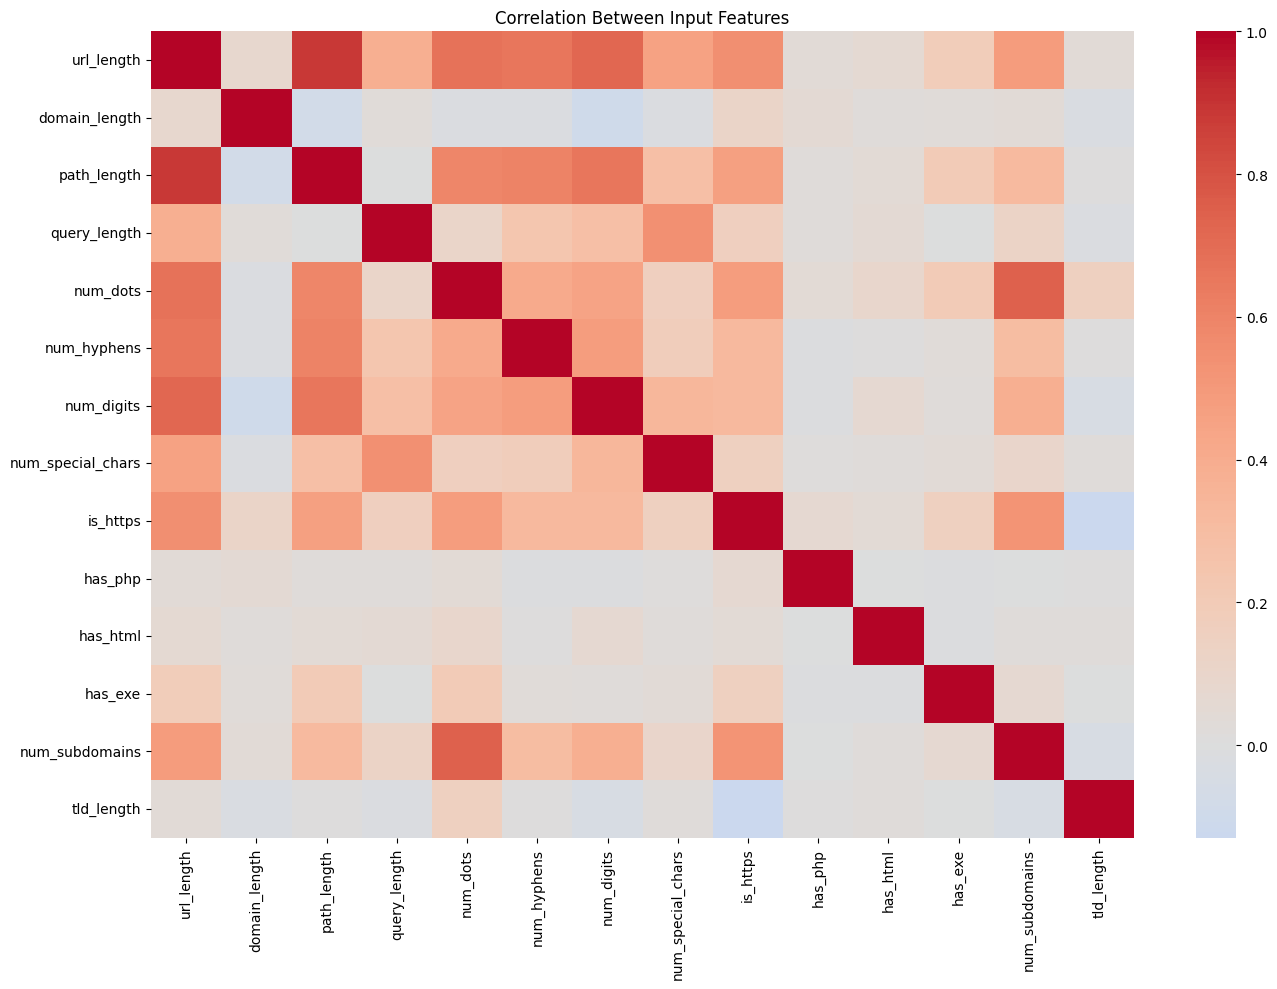

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = X_train.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information": mi_scores
}).sort_values(
    by="Mutual Information",
    ascending=False
)

display(feature_scores)

,Feature,Mutual Information
2,path_length,0.688087
0,url_length,0.615427
6,num_digits,0.380071
4,num_dots,0.340796
12,num_subdomains,0.324090
8,is_https,0.266436
7,num_special_chars,0.103350
5,num_hyphens,0.051806
1,domain_length,0.037828
13,tld_length,0.018971


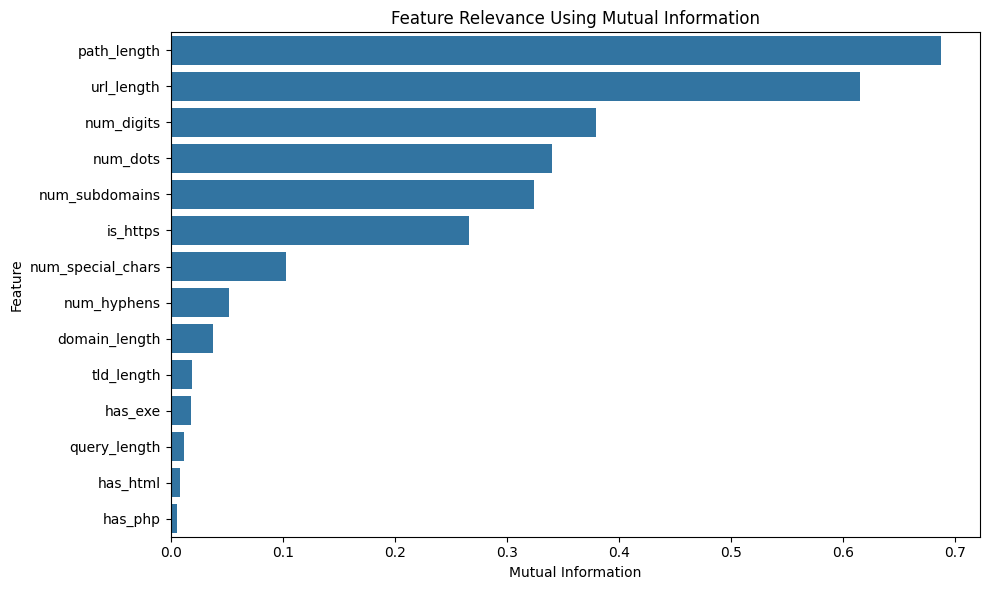

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_scores,
    x="Mutual Information",
    y="Feature"
)

plt.title("Feature Relevance Using Mutual Information")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline Precision:",
      precision_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

print("Baseline Recall:",
      recall_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

print("Baseline F1-score:",
      f1_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

Baseline Accuracy: 0.5
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0

Confusion Matrix:
[[3968    0]
 [3968    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      1.00      0.67      3968
           1       0.00      0.00      0.00      3968

    accuracy                           0.50      7936
   macro avg       0.25      0.50      0.33      7936
weighted avg       0.25      0.50      0.33      7936



## Feature Analysis and Baseline Findings

1. The training set contains 31,740 observations and the test set contains 7,936 observations.
2. Mutual information ranked `path_length` and `url_length` as the two most informative features in the initial analysis.
3. The correlation heatmap revealed relationships among some URL-related features.
4. The DummyClassifier achieved 50% accuracy, with zero precision, recall and F1-score for class 1.
5. The baseline demonstrates the need for a model that learns meaningful patterns from the URL features.

These results provide a reference point for evaluating machine-learning classifiers.